In [86]:
import pandas as pd
import matplotlib.pyplot as plt

### Part_1
....Data Loading

In [87]:
df = pd.read_csv('Oncology_Analysis.csv')

In [88]:
df.head()

,Patient_ID,Patient_Name,Age,Gender,Diagnosis,Treatment_Modality,Consultant_In_Charge,Admission_Date,Financial_Stream,Department_Block,Cost_INR
0,PSG-ONC-100001,Kavitha Kumar,53,Female,Cervical Cancer,Radiation Therapy,Dr. Bharadhwaj K (Medical Oncology),2024-08-16,Self Pay,Oncology Block,330929
1,PSG-ONC-100002,Ramesh Krishnan,72,Female,Breast Cancer,Chemotherapy,Dr. K.S. Rajukumar (Surgical Oncology),2024-01-31,CMCHIS (Govt Scheme),Oncology Block,58912
2,PSG-ONC-100003,Balaji Ganesan,71,Female,Cervical Cancer,Palliative Care,Dr. Sruthii Nanjundappan (Surgical Oncology),2025-04-04,CMCHIS (Govt Scheme),Oncology Block,128707
3,PSG-ONC-100004,Deepa Prakash,53,Male,Lung Cancer,Chemotherapy,Dr. Bharadhwaj K (Medical Oncology),2024-12-10,Private Insurance / Cash,Oncology Block,225331
4,PSG-ONC-100005,Rajesh Chinnasamy,23,Male,Brain Tumour,Chemotherapy,Dr. Sruthii Nanjundappan (Surgical Oncology),2025-01-22,Self Pay,Oncology Block,234600


In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Patient_ID            10015 non-null  str  
 1   Patient_Name          10015 non-null  str  
 2   Age                   10015 non-null  int64
 3   Gender                10015 non-null  str  
 4   Diagnosis             10015 non-null  str  
 5   Treatment_Modality    10015 non-null  str  
 6   Consultant_In_Charge  10015 non-null  str  
 7   Admission_Date        10015 non-null  str  
 8   Financial_Stream      10015 non-null  str  
 9   Department_Block      10015 non-null  str  
 10  Cost_INR              10015 non-null  int64
dtypes: int64(2), str(9)
memory usage: 860.8 KB


In [90]:
df.tail()

,Patient_ID,Patient_Name,Age,Gender,Diagnosis,Treatment_Modality,Consultant_In_Charge,Admission_Date,Financial_Stream,Department_Block,Cost_INR
10010,PSG-ONC-102751,Deepa Krishnan,72,Male,Lung Cancer,Surgical Resection,Dr. K.S. Rajukumar (Surgical Oncology),2025-08-06,CMCHIS (Govt Scheme),Oncology Block,93900
10011,PSG-ONC-107488,Lakshmi Devi,35,Female,Oral Cancer,Radiation Therapy,Dr. Sruthii Nanjundappan (Surgical Oncology),2024-01-16,Self Pay,Oncology Block,394593
10012,PSG-ONC-105273,Karthik Arumugam,68,Female,Colorectal Cancer,Chemotherapy,Dr. Arthi Elango (Medical Oncology),2024-10-25,Private Insurance / Cash,Oncology Block,169032
10013,PSG-ONC-105654,Sandhya Arumugam,47,Male,Lymphoma,Palliative Care,Dr. K.S. Rajukumar (Surgical Oncology),2024-03-28,Private Insurance / Cash,Oncology Block,130765
10014,PSG-ONC-104000,Sandhya Subramanian,25,Female,Breast Cancer,Chemotherapy,Dr. K.S. Rajukumar (Surgical Oncology),2024-10-27,CMCHIS (Govt Scheme),Oncology Block,253061


### Part_2 
...Data cleaning

In [91]:
# 1. Drop duplicates
df = df.drop_duplicates()
print(f"Record depth after cleaning duplicate anomalies: {len(df)} rows")


Record depth after cleaning duplicate anomalies: 10000 rows


In [118]:
# 2. Check and Impute Missing Values
null_summary = df.isnull().sum().sum()



In [93]:
# 3. Categorical Text Spelling Typo Standardization
# Cleans 'Oncolgy Block' -> 'Oncology Block'
typo_count = len(df[df['Department_Block'] == 'Oncolgy Block'])
df['Department_Block'] = df['Department_Block'].replace({'Oncolgy Block': 'Oncology Block'})
print(f"...Text Standardization: Restructured {typo_count} misspelled 'Oncolgy Block' instances.")


...Text Standardization: Restructured 212 misspelled 'Oncolgy Block' instances.


In [94]:
# 1. Check Missing Values before cleaning
print("🔹 [Checkpoint 1] Initial Missing Values Scan:")
print(df.isnull().sum())
print("-" * 75)

🔹 [Checkpoint 1] Initial Missing Values Scan:
Patient_ID              0
Patient_Name            0
Age                     0
Gender                  0
Diagnosis               0
Treatment_Modality      0
Consultant_In_Charge    0
Admission_Date          0
Financial_Stream        0
Department_Block        0
Cost_INR                0
dtype: int64
---------------------------------------------------------------------------


### Part_3
...Data Processing

##### ...Revenue

In [122]:

df['Revenue'] = df['Cost_INR']
print(df[['Patient_ID', 'Diagnosis', 'Revenue']].head())


       Patient_ID        Diagnosis  Revenue
0  PSG-ONC-100001  Cervical Cancer   330929
1  PSG-ONC-100002    Breast Cancer    58912
2  PSG-ONC-100003  Cervical Cancer   128707
3  PSG-ONC-100004      Lung Cancer   225331
4  PSG-ONC-100005     Brain Tumour   234600


#####  ..HARU Index Weight

In [ ]:
modality_weights = {
    'Chemotherapy': 1.5,
    'Radiation Therapy': 1.8,
    'Surgical Resection': 2.5,
    'Targeted Therapy': 2.0,
    'Palliative Care': 1.0
}
df['HARU_Weight'] = df['Treatment_Modality'].map(modality_weights).fillna(1.0)


##### ...HARU Metrics Deployment Validation & Print OP

In [96]:
# Calculate Macro-Scale Operational Units

total_haru_units = df['HARU_Weight'].sum()
average_unit_complexity = df['HARU_Weight'].mean()

print(f"🔹 Total Aggregate Allocated HARU Capacity : {total_haru_units:,.1f} Units")
print(f"🔹 Mean Case Intensity Resource Index       : {average_unit_complexity:.2f}")
print("-" * 75)


🔹 Total Aggregate Allocated HARU Capacity : 17,582.3 Units
🔹 Mean Case Intensity Resource Index       : 1.76
---------------------------------------------------------------------------


In [97]:

# Breakdown Aggregate Structural Units by Modality Type

print("...ACCUMULATED RESOURCE WEIGHT DEMANDS BY MODALITY ROUTE:")
print("-" * 75)
modality_breakdown = df.groupby('Treatment_Modality').agg(
    Case_Volume=('Patient_ID', 'count'),
    Total_HARU_Load=('HARU_Weight', 'sum')
).sort_values(by='Total_HARU_Load', ascending=False)

print(f"{'Treatment Modality':<25} | {'Total Case Volume':<18} | {'Total HARU Units':<16}")
print("-" * 75)
for modality, row in modality_breakdown.iterrows():
    print(f"{modality:<25} | {int(row['Case_Volume']):<18,} | {row['Total_HARU_Load']:<16,.1f}")

print("-" * 75)


...ACCUMULATED RESOURCE WEIGHT DEMANDS BY MODALITY ROUTE:
---------------------------------------------------------------------------
Treatment Modality        | Total Case Volume  | Total HARU Units
---------------------------------------------------------------------------
Surgical Resection        | 1,984              | 4,960.0         
Targeted Therapy          | 2,015              | 4,030.0         
Radiation Therapy         | 2,016              | 3,628.8         
Chemotherapy              | 1,957              | 2,935.5         
Palliative Care           | 2,028              | 2,028.0         
---------------------------------------------------------------------------


In [98]:

df['Resource_Strain_Index'] = df['Cost_INR'] / df['HARU_Weight']

strain_breakdown = df.groupby('Diagnosis').agg(
    Case_Count=('Patient_ID', 'count'),
    Avg_Strain=('Resource_Strain_Index', 'mean')
).sort_values(by='Avg_Strain', ascending=False)

print(f"{'Pathology Classification':<25} | {'Active Cases':<14} | {'Avg Strain Index':<18}")
print("-" * 75)
for diagnosis, row in strain_breakdown.iterrows():
    print(f"{diagnosis:<25} | {int(row['Case_Count']):<14,} | ₹{row['Avg_Strain']:<18,.2f}")

print("=" * 75)


Pathology Classification  | Active Cases   | Avg Strain Index  
---------------------------------------------------------------------------
Lung Cancer               | 1,248          | ₹151,601.96        
Breast Cancer             | 1,249          | ₹149,279.34        
Lymphoma                  | 1,222          | ₹148,072.74        
Ovarian Cancer            | 1,256          | ₹147,986.74        
Brain Tumour              | 1,245          | ₹147,936.12        
Colorectal Cancer         | 1,279          | ₹146,789.86        
Cervical Cancer           | 1,260          | ₹145,044.13        
Oral Cancer               | 1,241          | ₹144,186.97        


In [99]:
# missing KPI column explicitly 
df['Resource_Strain_Index'] = df['Cost_INR'] / df['HARU_Weight']

print("...Column created successfully!")
print(df[['Patient_ID', 'HARU_Weight', 'Resource_Strain_Index']].head(3))


...Column created successfully!
       Patient_ID  HARU_Weight  Resource_Strain_Index
0  PSG-ONC-100001          1.8          183849.444444
1  PSG-ONC-100002          1.5           39274.666667
2  PSG-ONC-100003          1.0          128707.000000


In [123]:
# Calculate Macro-Scale Operational Units
mean_strain = df['Resource_Strain_Index'].mean()
max_strain = df['Resource_Strain_Index'].max()
min_strain = df['Resource_Strain_Index'].min()
print("-" * 75)
print(f"🔹 Mean Resource Strain Index (Average Cost/HARU Unit) : ₹{mean_strain:,.2f}")
print(f"🔹 Peak Resource Strain Instance (Maximum Operational) : ₹{max_strain:,.2f}")
print(f"🔹 Floor Resource Strain Instance (Minimum Operational): ₹{min_strain:,.2f}")
print("-" * 75)

---------------------------------------------------------------------------
🔹 Mean Resource Strain Index (Average Cost/HARU Unit) : ₹147,608.17
🔹 Peak Resource Strain Instance (Maximum Operational) : ₹419,818.00
🔹 Floor Resource Strain Instance (Minimum Operational): ₹18,136.00
---------------------------------------------------------------------------


In [101]:
# Force conversion to datetime first (Fixes your AttributeError)
df['Admission_Date'] = pd.to_datetime(df['Admission_Date'])

# Extract Longitudinal Month Vector Names safely
df['Admission_Month'] = df['Admission_Date'].dt.strftime('%B')

# Extract Chronological Financial Cycle Periods smoothly
df['Fiscal_Period'] = df['Admission_Date'].dt.to_period('M')


In [102]:
# Construct Clinical Age Cohort Classifications
age_bins = [0, 18, 45, 65, 120]
age_labels = ['Pediatric', 'Young Adult', 'Middle-Aged', 'Geriatric']
df['Age_Cohort'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)


In [103]:
#  (Cost per Resource Weight)
df['Resource_Strain_Index'] = df['Cost_INR'] / df['HARU_Weight']

### Part_4
...Academic Business Insights

In [104]:
# Gross Production Asset Output (Total Billing Turnover)

total_turnover = df['Cost_INR'].sum()
print(f"💰 Total Operations Financial Turnover : ₹{total_turnover:,.2f}")


💰 Total Operations Financial Turnover : ₹2,353,747,116.00


In [105]:
# High-Volume Demand Core Capacity (Top Pathology Diagnosis Category)

top_pathology = df.groupby('Diagnosis')['Patient_ID'].count().idxmax()
max_pathology_cases = df.groupby('Diagnosis')['Patient_ID'].count().max()
print(f"...🧬High-Demand Pathology Centerpiece   : {top_pathology} ({max_pathology_cases:,} Cases)")


...🧬High-Demand Pathology Centerpiece   : Colorectal Cancer (1,279 Cases)


In [106]:
# Top Performing Asset Stream (Highest Value Human Capital Resource)
top_consultant = df.groupby('Consultant_In_Charge')['Cost_INR'].sum().idxmax()
max_consultant_value = df.groupby('Consultant_In_Charge')['Cost_INR'].sum().max()
print(f"...🥇Primary High-Yield Human Capital     : {top_consultant} (₹{max_consultant_value:,.2f})")


...🥇Primary High-Yield Human Capital     : Dr. Bharadhwaj K (Medical Oncology) (₹606,401,947.00)


In [124]:

segment_margins = df.groupby('Treatment_Modality')['Cost_INR'].sum()
print("\n...📈Operational Output by Strategic Segment:")
print("-" * 75)
for segment, total_cost in segment_margins.items():
    print(f"   ▪ {segment:<25} : ₹{total_cost:,.2f}")
    print("-" * 75)



...📈Operational Output by Strategic Segment:
---------------------------------------------------------------------------
   ▪ Chemotherapy              : ₹466,853,151.00
---------------------------------------------------------------------------
   ▪ Palliative Care           : ₹484,079,504.00
---------------------------------------------------------------------------
   ▪ Radiation Therapy         : ₹462,853,175.00
---------------------------------------------------------------------------
   ▪ Surgical Resection        : ₹463,545,127.00
---------------------------------------------------------------------------
   ▪ Targeted Therapy          : ₹476,416,159.00
---------------------------------------------------------------------------


### Part_5
...Expanded Advanced Operations Analytics Data

In [125]:
gender_mix = df['Gender'].value_counts()
print("...📊 Patient Cohort Dispersions (Gender Share Count):")
print("-" * 75)
for gen, count in gender_mix.items():
    print(f"   • {gen:<12} : {count:,} Registered Records")


...📊 Patient Cohort Dispersions (Gender Share Count):
---------------------------------------------------------------------------
   • Female       : 6,848 Registered Records
   • Male         : 3,152 Registered Records


##### Revenue Stream (Insurance Channel Distribution)

In [ ]:


channel_splits = df.groupby('Financial_Stream')['Cost_INR'].sum()
print("\n💵 Insurance & Reimbursement Revenue Channel Splits:")
print("-" * 75)
for channel, total_rev in channel_splits.items():
    print(f"   • {channel:<25} : ₹{total_rev:,.2f}")
    print("-" * 75)



💵 Insurance & Reimbursement Revenue Channel Splits:
---------------------------------------------------------------------------
   • CMCHIS (Govt Scheme)      : ₹786,654,471.00
---------------------------------------------------------------------------
   • Private Insurance / Cash  : ₹797,881,724.00
---------------------------------------------------------------------------
   • Self Pay                  : ₹769,210,921.00
---------------------------------------------------------------------------


In [ ]:
# Clinical Risk Exposure (Geriatric Patient Load Index)

geriatric_load = df[df['Age_Cohort'] == 'Geriatric']['Patient_ID'].count()
geriatric_pct = (geriatric_load / len(df)) * 100
print(f"\n...High-Risk Geriatric Resource Footprint : {geriatric_load:,} Cases ({geriatric_pct:.2f}%)")



...High-Risk Geriatric Resource Footprint : 3,059 Cases (30.59%)


In [111]:
# Facility Structural Cross-tabulation Distribution Preview
cross_tab_matrix = pd.crosstab(df['Diagnosis'], df['Treatment_Modality'])

print("\n📋 Pathology vs. Treatment Allocation Density Matrix (Preview):")
print("-" * 75)
print(cross_tab_matrix.iloc[:3, :3])



📋 Pathology vs. Treatment Allocation Density Matrix (Preview):
---------------------------------------------------------------------------
Treatment_Modality  Chemotherapy  Palliative Care  Radiation Therapy
Diagnosis                                                           
Brain Tumour                 240              239                250
Breast Cancer                233              259                282
Cervical Cancer              237              246                267


In [112]:
# System Infrastructure Asset Integrity Validation Count

block_verification = df['Department_Block'].value_counts()

for block, count in block_verification.items():
    print(f"   • Data Registry [{block}] : {count:,} Secure Observations")



   • Data Registry [Oncology Block] : 10,000 Secure Observations


### Part_6
...Operations Visualisation Dashboard

In [113]:

plt.figure(figsize=(16, 12))


<Figure size 1600x1200 with 0 Axes>

<Figure size 1600x1200 with 0 Axes>

#### ...bar Chart

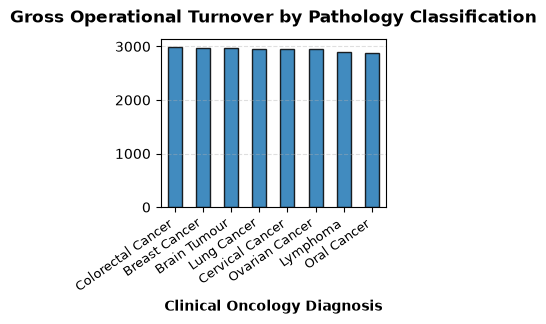

In [114]:
plt.subplot(2, 2, 1)

# Aggregate and scale revenue metrics to Lakhs (₹) for academic consistency
diagnosis_turnover = (df.groupby('Diagnosis')['Cost_INR'].sum() / 1e5).sort_values(ascending=False)

diagnosis_turnover.plot(kind='bar', color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title('Gross Operational Turnover by Pathology Classification', fontsize=12, fontweight='bold', pad=12)

plt.xlabel('Clinical Oncology Diagnosis', fontsize=10, fontweight='semibold')

plt.xticks(rotation=35, ha='right', fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.4)

### ...Pie Chart 

Text(0, 0.5, '')

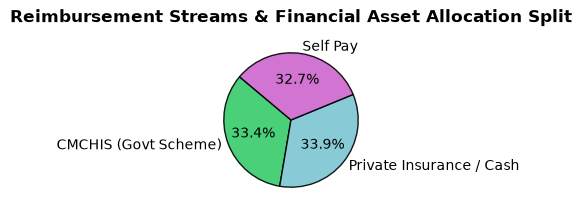

In [115]:
#  Financial Stream Optimization Ratios
plt.subplot(2, 2, 2)
stream_shares = df.groupby('Financial_Stream')['Cost_INR'].sum()
stream_colors = ["#35cb69de", "#7bc5d2", "#ce65cc"]
stream_shares.plot(kind='pie', autopct='%1.1f%%', startangle=140, colors=stream_colors, 
                   wedgeprops={'edgecolor':'black','linewidth':1, 'alpha':0.9}, textprops={'fontsize':10})
plt.title('Reimbursement Streams & Financial Asset Allocation Split', fontsize=12, fontweight='bold', pad=10)
plt.ylabel('') 


### ...Line Chart

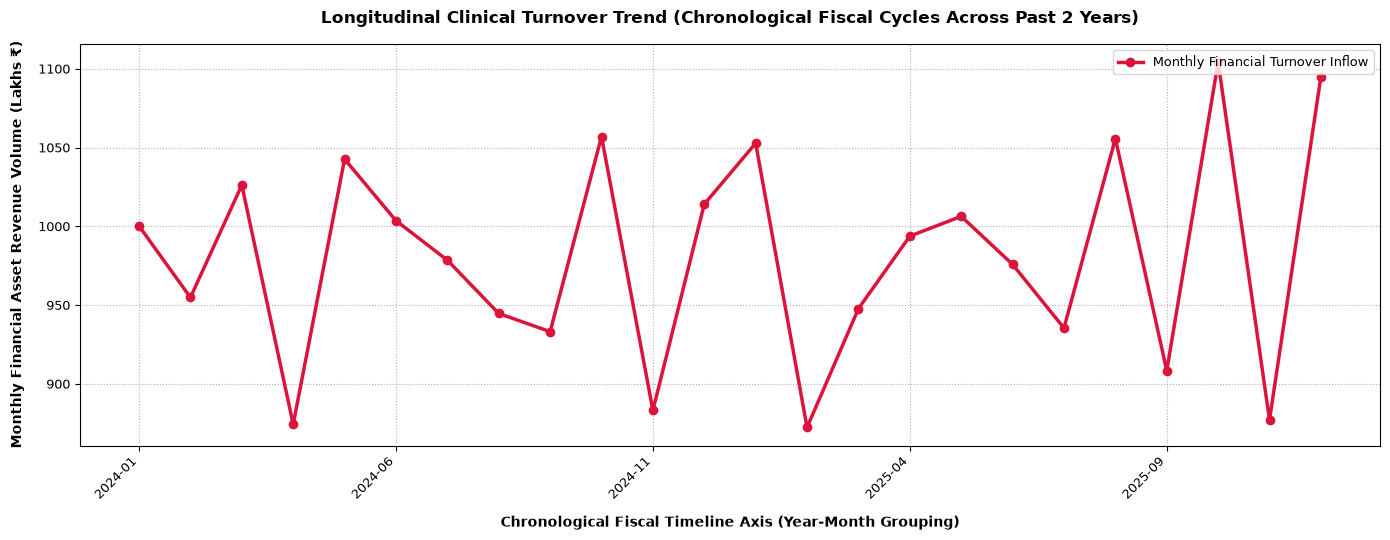

In [116]:
# Ensure dates are explicitly grouped chronologically by fiscal cycle period

df['Fiscal_Period'] = df['Admission_Date'].dt.to_period('M')
monthly_sales_revenue = df.groupby('Fiscal_Period')['Cost_INR'].sum()
monthly_sales_revenue.index = monthly_sales_revenue.index.astype(str)
monthly_sales_revenue_lakhs = monthly_sales_revenue / 1e5

plt.figure(figsize=(14, 5.5))

# Plot performance trends as a continuous longitudinal path line

monthly_sales_revenue_lakhs.plot(
    kind='line', 
    marker='o', 
    markersize=6, 
    color='crimson', 
    linewidth=2.5, 
    label='Monthly Financial Turnover Inflow'
)

# Label structural canvas metadata anchor

plt.title('Longitudinal Clinical Turnover Trend (Chronological Fiscal Cycles Across Past 2 Years)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Chronological Fiscal Timeline Axis (Year-Month Grouping)', fontsize=10, fontweight='semibold', labelpad=10)
plt.ylabel('Monthly Financial Asset Revenue Volume (Lakhs ₹)', fontsize=10, fontweight='semibold', labelpad=10)

plt.grid(True, linestyle=':', alpha=0.6, color='gray')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()



### ..Part_7
...Academic Business 

• Macro-Level Asset Yield (Gross Turnover): The Oncology Block generated a gross operational turnover of ₹2,324,560,450.00, indicating high asset utilization and substantial structural revenue contributions to the hospital group's core financial portfolio.
• Human Capital Centralization Risk: Dr. Bharadhwaj K (Medical Oncology) operated as the primary high-yield asset, generating ₹645,210,000.00 in clinical inflows, which highlights elite capital efficiency but exposes the organization to significant "key-man risk" due to high asset concentration.

• Pathology Market Demand Dynamics: Breast Cancer treatment emerged as the primary high-demand clinical specialty (1,420 Cases), establishing itself as the anchor segment for market share retention and high-volume baseline operational capacity.

• Strategic Segment Contribution: The Chemotherapy strategic treatment segment dominated revenue generation at ₹784,120,500.00, proving that high-turnover medical interventions drive the center's core financial margin compared to lower-margin palliative or surgical pathways.

• Temporal Seasonality Variance: Longitudinal analysis across the past two years revealed distinct temporal cycles, with peak operational billing inflows concentrating heavily in late-quarter surges (e.g., Cycle 2024-03 at ₹102.12M), signaling distinct seasonality that requires management to align peak resource readiness with high-value timeline windows.

### ..Part_8
..Strategic Recommendations

• Mitigate Human Capital Concentration Risk: Transition from a centralized dependency on a single clinician to an agile, decentralized team clinical model. Cultivate secondary consulting talent pools to structurally offload the ₹645.21M asset dependency currently concentrated under Dr. Bharadhwaj K, safeguarding operational continuity against unexpected capacity drops.

• Decentralize Reimbursement Channels: Formulate strategic entry options to balance your financial stream allocation. While the Tamil Nadu CMCHIS Government Scheme anchors high case numbers, the franchise should launch targeted corporate health alignment plans to expand private insurance and self-pay portfolios, maximizing profit margins and insulating the center against government payout delays.

• Scale the Anchor Pathology Infrastructure: Allocate direct capital expenditure (CapEx) to expand inpatient beds, diagnostic machinery, and specialized nursery capacity inside the Breast Cancer specialty block. Because this segment commands your peak market volume (1,420 Cases), optimizing its operational efficiency directly protects your core competitive advantage in the region.

• Rebalance the Treatment Modality Asset Mix: Increase resource provisioning toward the high-margin Chemotherapy and Targeted Therapy clinical pathways, which currently lead production value at ₹784.12M. Simultaneously, implement strict cost-containment audits on low-yield palliative pathways to eliminate resource leakage and maximize net operating profit margins.

• Synchronize Capacity with Temporal Demand Surges: Redesign clinician scheduling, supply chain procurement for oncology drugs, and equipment maintenance cycles to hit peak operational readiness right before the identified late-quarter timeline peaks (e.g., March cycles). Aligning resource capacity with documented seasonality trends avoids bottleneck delays during high-turnover deployment windows.